## One Courier’s Multi-Day Delivery Cadence (Flag 9)

### Dataset Overview
A multi-day case using LaDe-style delivery times, acceptance times, explicit service windows, route labels, and linked GPS segments for one courier.

The notebook exposes a primary table and a supporting table (`courier_trajectories.csv`).

Goal: Summarize this courier’s delivery patterns from trajectories observed over several days.

Role: Last-mile delivery operations analyst


Category: multi-day delivery cadence and service-window acceptance

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "delivery_tasks.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does the time interval between consecutive deliveries change over the course of each day?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

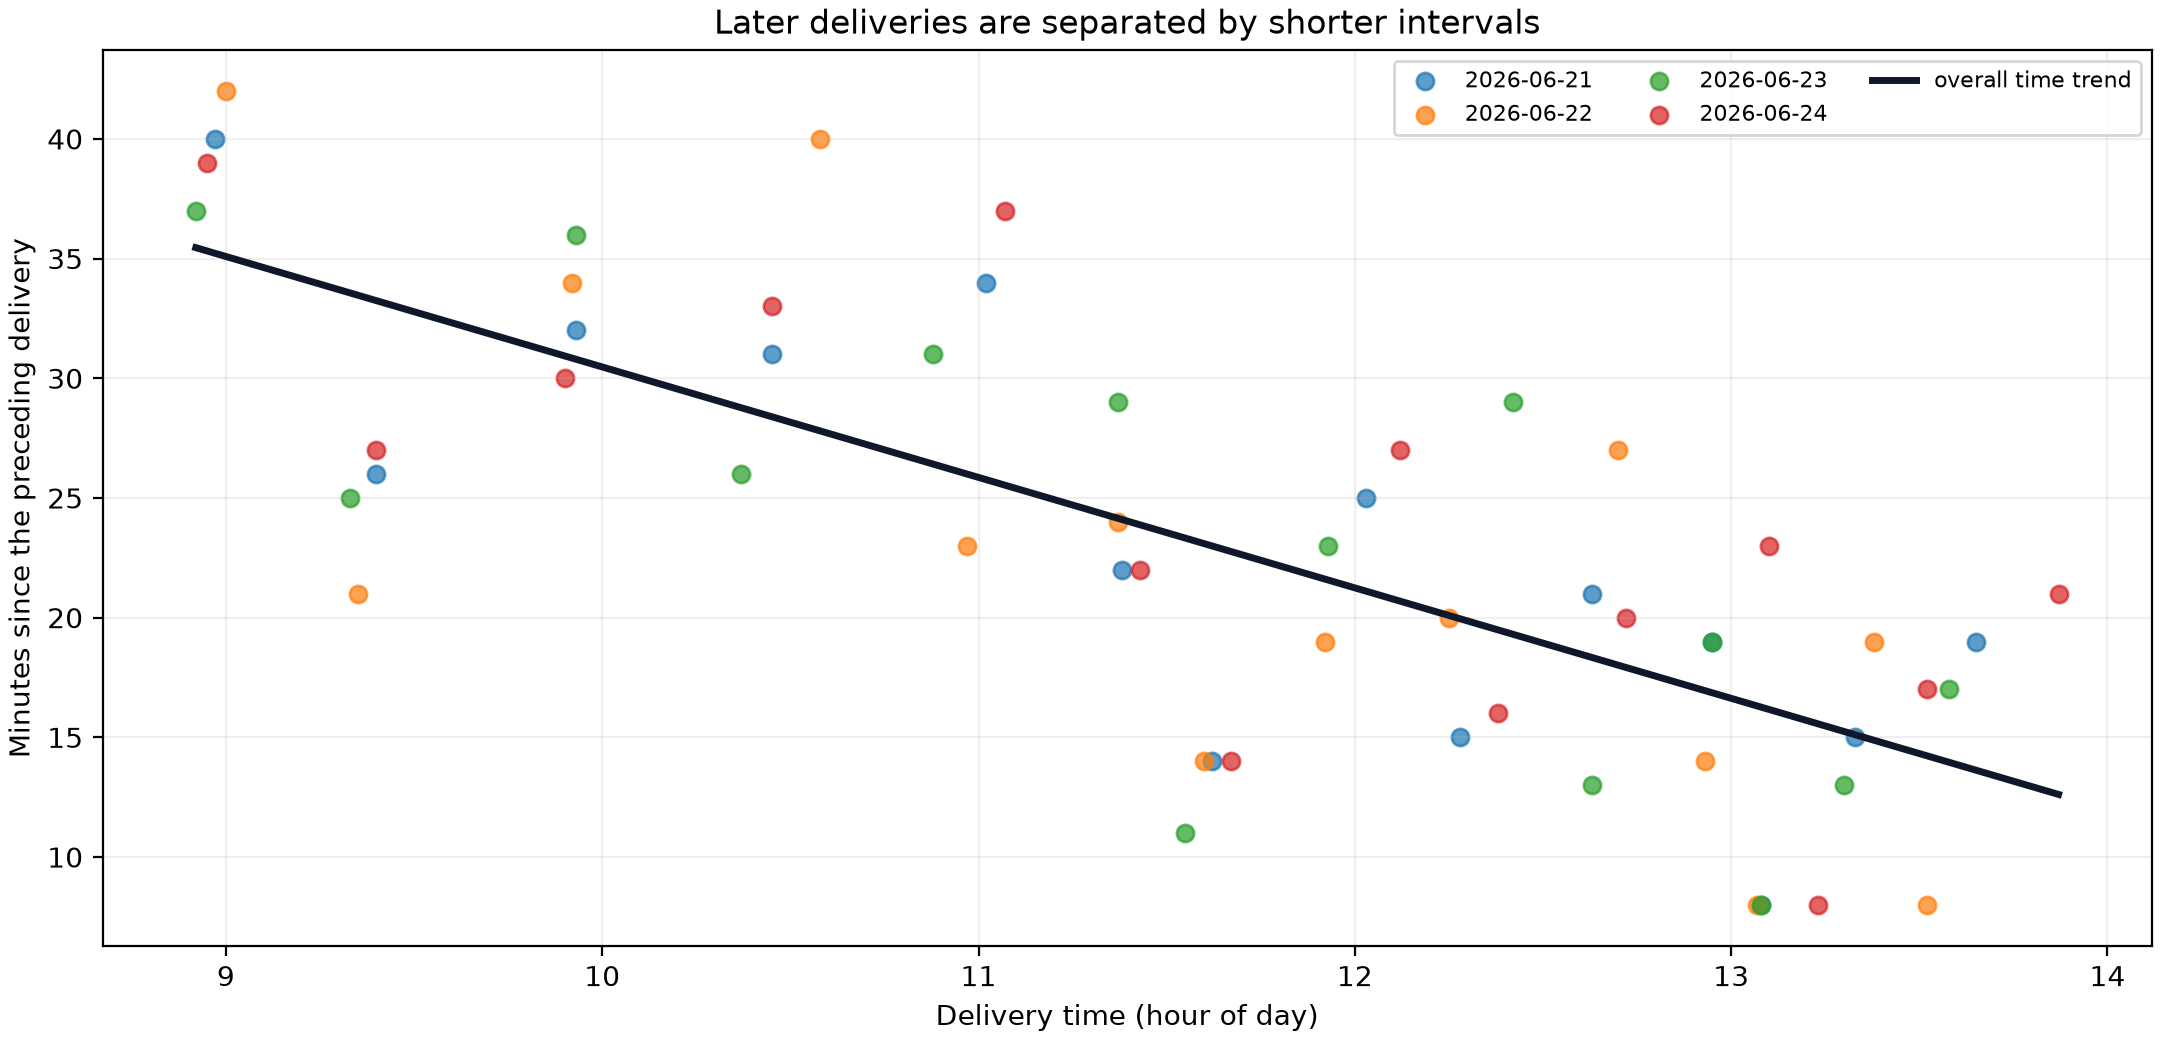

In [ ]:

# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/delivery_gap_over_time.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "time_ordered_delivery_cadence",
  "insight": "Later in the day, the time interval between consecutive deliveries becomes shorter.",
  "plot": {
    "plot_type": "time_gap_scatter_with_trend",
    "title": "Delivery Interval over Time",
    "file": "visualizations/delivery_gap_over_time.png",
    "description": "Across the supplied days, later delivery events are associated with shorter intervals from the prior completed delivery."
  },
  "question": "How does the time interval between consecutive deliveries change over the course of each day?",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "delivery_time",
    "task_id",
    "route_id"
  ]
}

### **Question 2**: After accounting for time of day, how does the delivery interval differ between central route positions and route edges?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

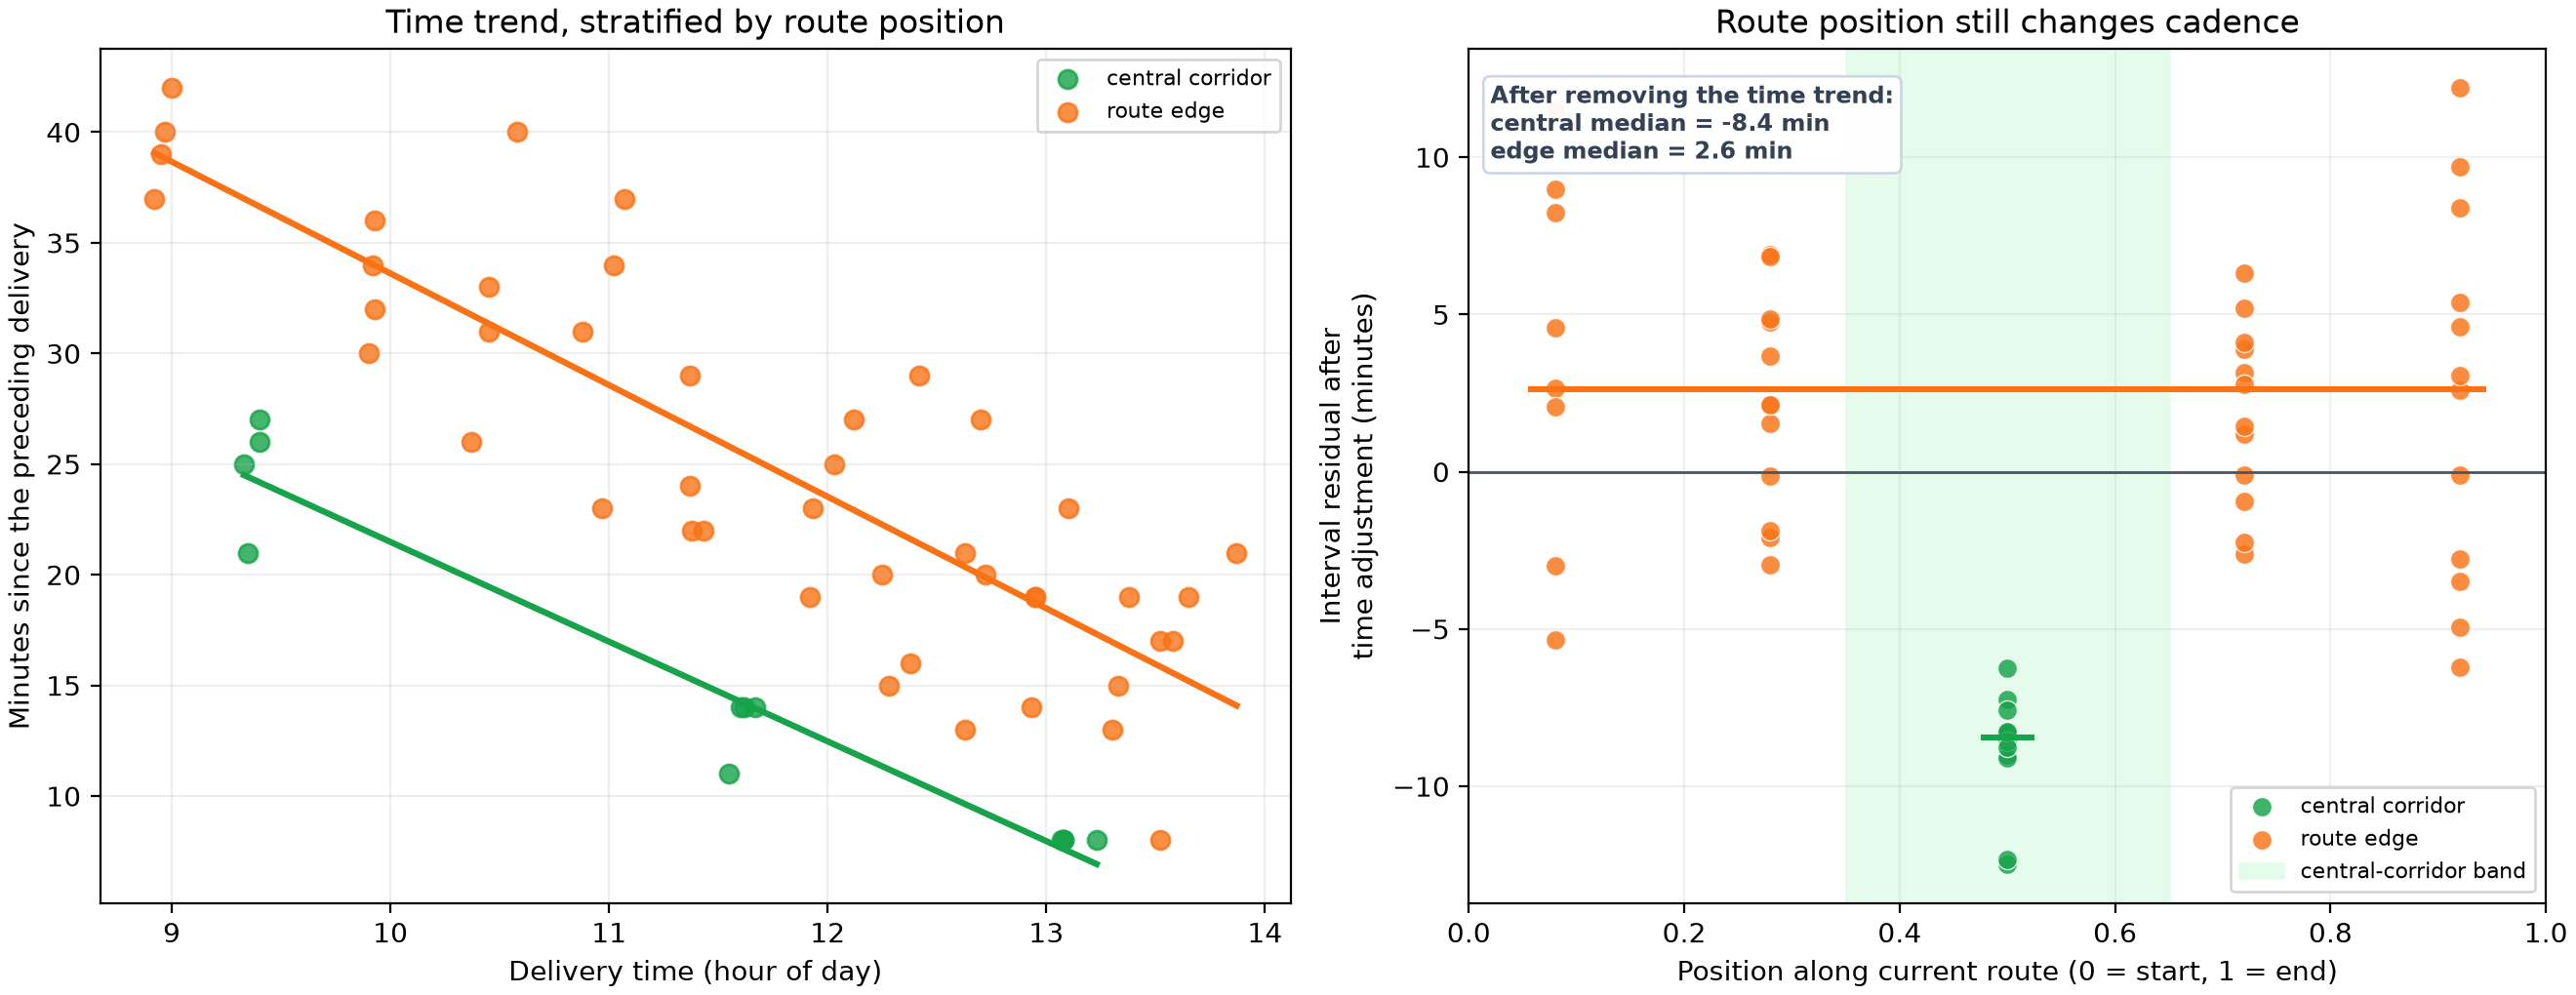

In [ ]:

# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/time_and_route_position_cadence.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "time_route_position_cadence",
  "insight": "Delivery cadence depends not only on time of day but also on the courier’s current position along the route: consecutive deliveries are more tightly spaced around the central corridor than near route edges.",
  "plot": {
    "plot_type": "time_stratified_scatter_and_route_position_residual_plot",
    "title": "Time and Route Position in Delivery Cadence",
    "file": "visualizations/time_and_route_position_cadence.png",
    "description": "The left panel shows the time trend by route position; the right panel removes that trend and exposes the independent central-corridor cadence advantage."
  },
  "question": "After accounting for time of day, how does the delivery interval differ between central route positions and route edges?",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "delivery_time",
    "gps_time",
    "gps_position",
    "task_id",
    "route_id"
  ]
}

### **Question 3**: How do consecutive-delivery interval distributions differ across the short, medium, and long routes?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

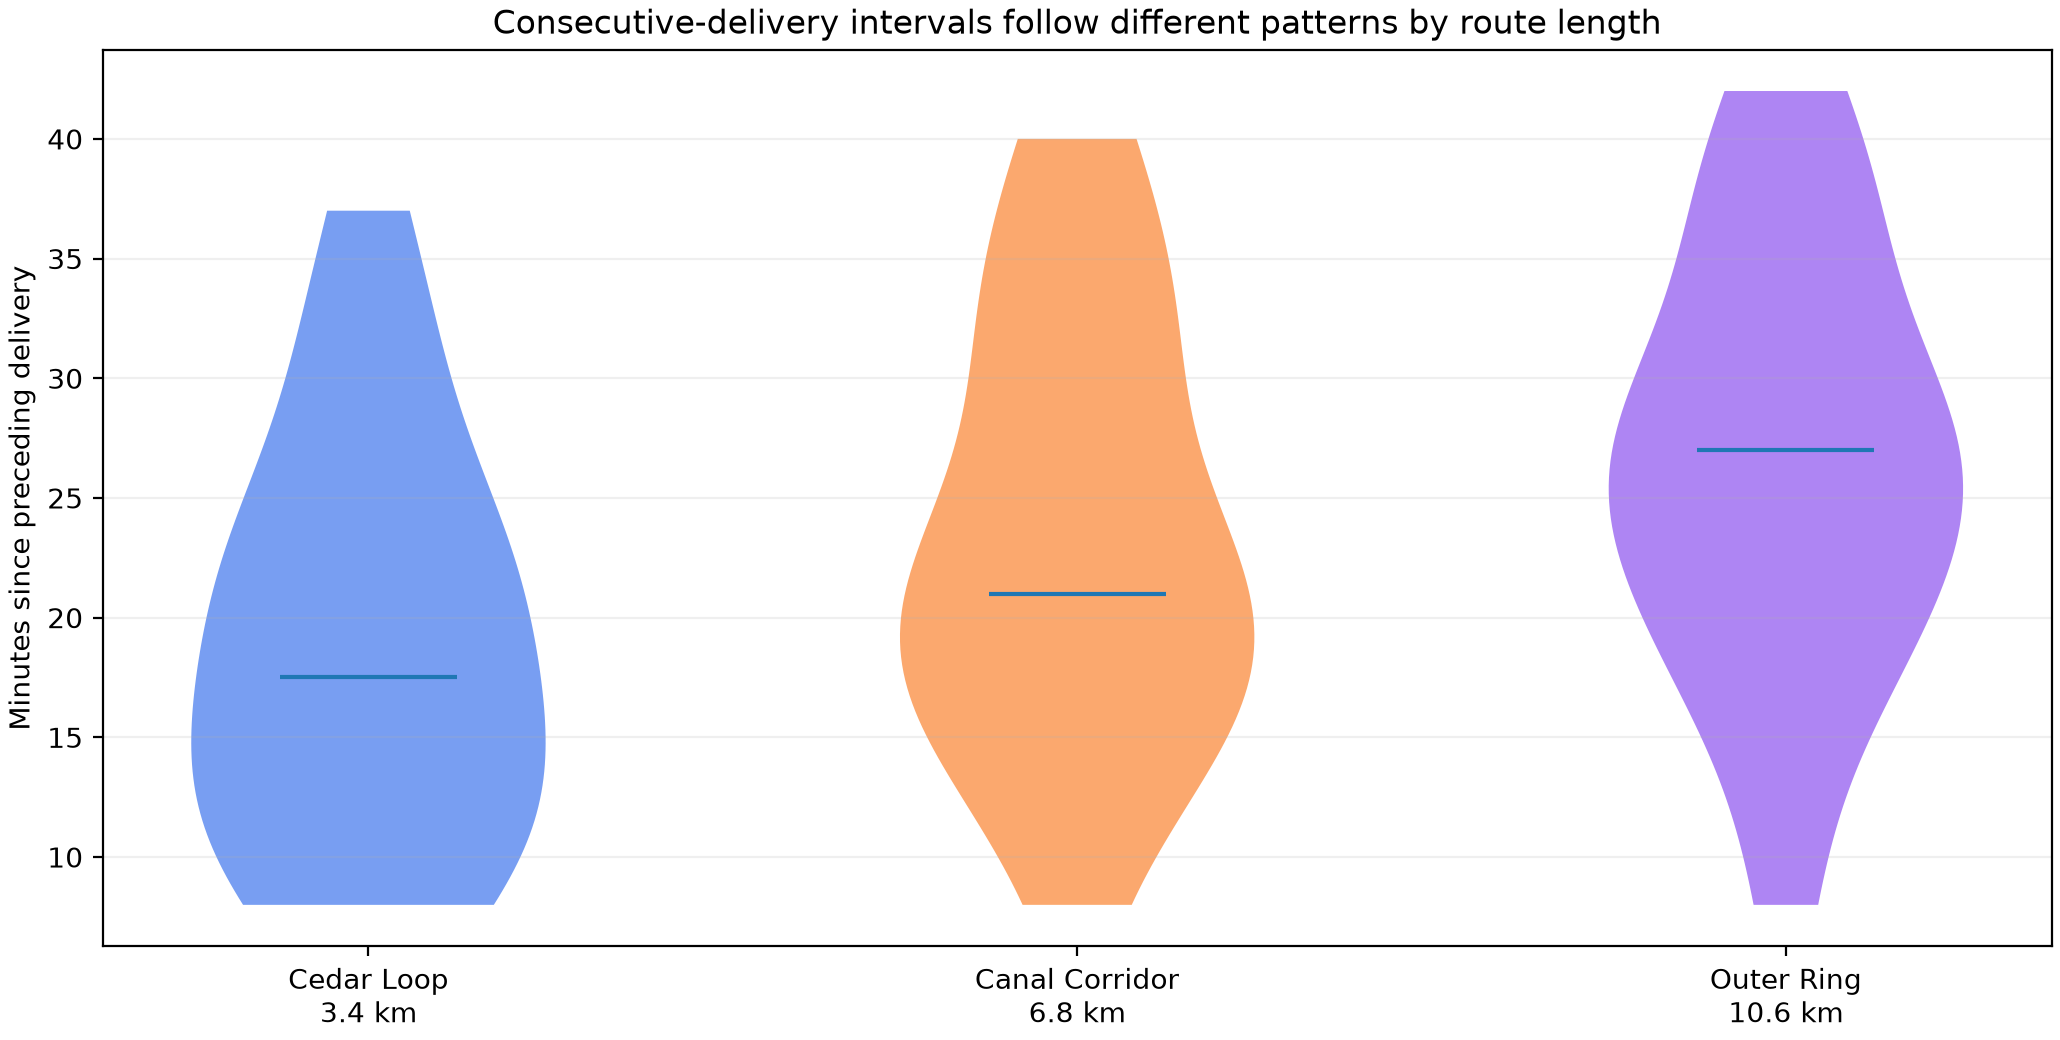

In [ ]:

# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/route_length_gap_patterns.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "route_length_delivery_interval_distribution",
  "insight": "Routes of different lengths have different consecutive-delivery interval patterns rather than a single shared cadence.",
  "plot": {
    "plot_type": "route_length_violin_distribution",
    "title": "Route Length and Consecutive-Delivery Intervals",
    "file": "visualizations/route_length_gap_patterns.png",
    "description": "The full interval distributions differ across the short, medium, and long route groups."
  },
  "question": "How do consecutive-delivery interval distributions differ across the short, medium, and long routes?",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "delivery_time",
    "gps_position",
    "task_id",
    "route_id"
  ]
}

### **Question 4**: When are delivery tasks accepted relative to their promised service windows, and are any accepted after the window closes?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

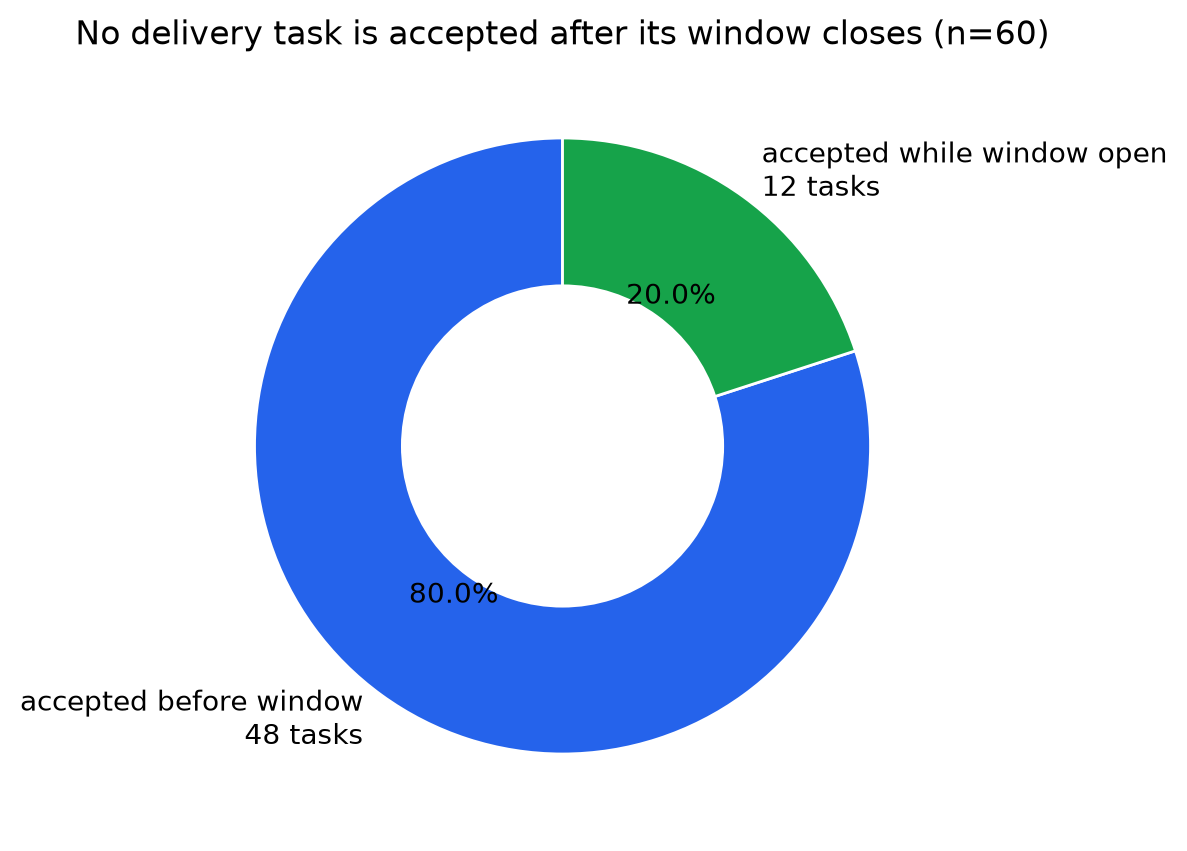

In [ ]:

# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/acceptance_relative_to_window.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "acceptance_time_relative_to_service_window",
  "insight": "This courier accepts delivery tasks either before their promised service windows begin or while the windows are open; no supplied task is accepted after its window closes.",
  "plot": {
    "plot_type": "service_window_acceptance_donut",
    "title": "Acceptance Relative to Promised Service Windows",
    "file": "visualizations/acceptance_relative_to_window.png",
    "description": "The donut summarizes the two observed acceptance states and explicitly records zero after-window acceptance."
  },
  "question": "When are delivery tasks accepted relative to their promised service windows, and are any accepted after the window closes?",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "time_window_start",
    "time_window_end",
    "task_id"
  ]
}

### Summary of Findings (Flag 9)

Across several workdays, this courier’s delivery cadence accelerates later in the day, but route position and route length also structure the interval between deliveries. All supplied tasks are accepted before or during their promised service windows.